# Programa 10. Evaluación de regresión

Noviembre 15, 2026

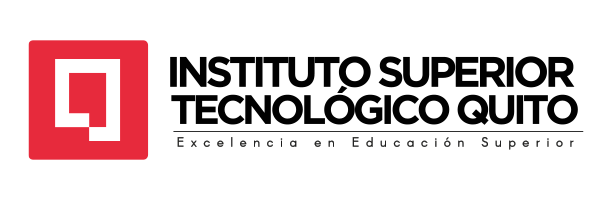

**Nombre:** Edgar Ulloa  
**Fecha:** *15-11-2026*    
**Link Repositorio:** https://github.com/eulloaitq/Fundamentos-de-Machine-Learning.git

## Evaluación de regresión

**Objetivo:** Aprender a separar datos, aplicar validación cruzada y evaluar un modelo SVR con MAE, RMSE y MAPE.

## Importación de librerías

Se importan **NumPy**, herramientas de **scikit-learn** para separar datos, estandarizar, entrenar y evaluar un modelo de regresión, y **Matplotlib** para visualizar las predicciones.

In [1]:
import numpy as np
from math import sqrt
from pprint import pprint
from sklearn import datasets
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate
from sklearn.model_selection import KFold
from sklearn.metrics import make_scorer
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
from sklearn import preprocessing

## Carga y exploración del conjunto de datos

La función load_diabetes() recupera un dataset que contiene 442 instancias, 10 atributos numéricos y un valor objetivo continuo que representa una medida de progresión de la enfermedad un año después de la medición inicial. **pprint** muestra el contenido del dataset y **np.shape** muestra las dimensiones de este.

In [2]:
# Cargar y explorar los datos
datos = datasets.load_diabetes()
pprint(datos)
print(np.shape(datos.data))

{'DESCR': '.. _diabetes_dataset:\n'
          '\n'
          'Diabetes dataset\n'
          '----------------\n'
          '\n'
          'Ten baseline variables, age, sex, body mass index, average blood\n'
          'pressure, and six blood serum measurements were obtained for each '
          'of n =\n'
          '442 diabetes patients, as well as the response of interest, a\n'
          'quantitative measure of disease progression one year after '
          'baseline.\n'
          '\n'
          '**Data Set Characteristics:**\n'
          '\n'
          ':Number of Instances: 442\n'
          '\n'
          ':Number of Attributes: First 10 columns are numeric predictive '
          'values\n'
          '\n'
          ':Target: Column 11 is a quantitative measure of disease progression '
          'one year after baseline\n'
          '\n'
          ':Attribute Information:\n'
          '    - age     age in years\n'
          '    - sex\n'
          '    - bmi     body mass index\n'

## Separación de atributos y objetivo

En esta pate se asignan los valores a dos variables. **X** contiene los diez atributos predictivos y **y** contiene el valor que se va a estimar. En el proceso de aprendizaje supervisado, el modelo aprende la relación entre ambos.

In [3]:
X = datos.data
y = datos.target
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (442, 10)
Dimensiones de y: (442,)


## Partición externa: entrenamiento y prueba

En la particion del dataset se reserva el **80%** de las instancias para el proceso de entrenamiento y el **20%** para realizar una evaluación final. Aqui **random_state=42** es un parametro que permite repetir la misma partición y el conjunto de prueba no debe utilizarse para ajustar el modelo.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Entrenamiento:", X_train.shape[0], "instancias")
print("Prueba:", X_test.shape[0], "instancias")

Entrenamiento: 353 instancias
Prueba: 89 instancias


## Estandarización

La función **StandardScaler** realiza el proceso de escalamiento restando la media y dividiendo por la desviación estándar. El ajuste de la función **fit** se hace **solo con entrenamiento** y luego se aplica en la prueba.

In [5]:
escalador = preprocessing.StandardScaler()
X_train_escalado = escalador.fit_transform(X_train)
X_test_escalado = escalador.transform(X_test)
print("Media aproximada de entrenamiento escalado:", np.round(X_train_escalado.mean(axis=0), 4))
# En la validación cruzada usaremos los datos originales con un Pipeline
# para ajustar el escalador dentro de cada partición.

Media aproximada de entrenamiento escalado: [ 0.  0. -0.  0. -0. -0.  0.  0.  0. -0.]


## Métricas de evaluación

La métrica de evaluación **MAE** representa el error absoluto medio es decir que cuanto menor sea es mejor, la métrica **RMSE** penaliza severamente los errores grandes y la métrica **MAPE** expresa el error porcentual medio y requiere valores reales distintos de cero.

In [6]:
# Métricas de evaluación.
metricas = {
  'MAE': 'neg_mean_absolute_error',
  'RMSE': make_scorer(lambda y, y_pred: sqrt(mean_squared_error(y, y_pred)), greater_is_better=False),
  'MAPE': make_scorer(lambda y, y_pred: np.mean(np.abs((y - y_pred) / y)) * 100, greater_is_better=False)}

## Definición del modelo

Se utiliza el modelo **SVR** (Support Vector Regression) con un núcleo RBF. El parametro **C** controla la penalización de los errores y el parametro **gamma** influye en el alcance de la función RBF.

In [7]:
from sklearn.pipeline import make_pipeline
alg = make_pipeline(
    preprocessing.StandardScaler(),
    SVR(C=10, gamma="scale", kernel="rbf")
)

## Validación cruzada interna de cinco particiones

La función **KFold(n_splits=5)** divide los datos de entrenamiento en cinco partes, de modo que en cada iteración el modelo se entrena con cuatro partes y se valida con la restante. El conjunto de prueba externo reservado permanece separado y se define el parametro **shuffle=True** para mezclar las instancias de forma reproducible.

In [8]:
results = cross_validate(
    alg, X_train, y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring=metricas
)

## Interpretación de las métricas de validación

La validación cruzada **cross_validate** devuelve los tiempos y resultados de cada partición. El signo negativo en test_MAE, test_RMSE y test_MAPE es una convención de scikit-learn, no significa que el error real sea negativo, por esta razón se presenta el promedio con valor positivo para facilitar su interpretación.

In [9]:
pprint(results)
print("\nPROMEDIOS DE VALIDACIÓN CRUZADA")
for nombre in metricas:
    errores = -results["test_" + nombre]
    print(f"{nombre}: {errores.mean():.4f} (desviación: {errores.std():.4f})")

{'fit_time': array([0.00529075, 0.00448036, 0.00523448, 0.00394607, 0.00449443]),
 'score_time': array([0.00419092, 0.00249624, 0.00422335, 0.00212455, 0.00321484]),
 'test_MAE': array([-48.26285616, -51.99094138, -42.19909846, -45.73437715,
       -50.39789838]),
 'test_MAPE': array([-32.83110657, -45.90028442, -37.74947192, -43.12401136,
       -44.16570536]),
 'test_RMSE': array([-57.68310314, -60.27338482, -51.94585761, -55.51382769,
       -63.98279561])}

PROMEDIOS DE VALIDACIÓN CRUZADA
MAE: 47.7170 (desviación: 3.4678)
RMSE: 57.8798 (desviación: 4.0945)
MAPE: 40.7541 (desviación: 4.8071)


## Entrenamiento final

Una vez que se ha fijado la configuración del modelo, este se entrena con todo el conjunto de entrenamiento externo reservado.

In [10]:
model = make_pipeline(
    preprocessing.StandardScaler(),
    SVR(C=10, gamma="scale", kernel="rbf")
)
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](10,)","[0.,0.,0.,...,0.,0.,0.]"


## Evaluación final sobre el conjunto de prueba

La función **predict()** obtiene estimaciones para las instancias nunca utilizadas durante el ajuste, también se calcula el **MAE** de prueba y se muestra el resultado, resulta que un MAE menor significa predicciones más próximas en promedio a los valores reales.

In [11]:
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
print("Resultados en prueba (MAE):", round(mae, 4))

Resultados en prueba (MAE): 41.3197


## Comparación de predicciones y valores reales

Aqui se muestran las primeras diez predicciones y sus valores reales correspondientes, las diferencias que se presentan son los errores de predicción.

In [12]:
# También podemos extraer las predicciones para cuánto difieren los valores predichos de los reales
print('Predicciones:   ', np.round(y_pred[:10], 1))
print('Valores reales: ', y_test[:10])

Predicciones:    [149.  172.2 152.9 212.3 110.1 122.3 227.3 191.8 106.7 103.9]
Valores reales:  [219.  70. 202. 230. 111.  84. 242. 272.  94.  96.]


## Gráfico de valores reales frente a predichos

Se define la funcion que genera el gráfico.

In [13]:
def grafica_real_vs_pred(y_true, y_pred, metricas, algoritmo):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(y_true, y_pred, edgecolors="black", alpha=0.65)
    limites = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(limites, limites, "k--", lw=2, label="Predicción perfecta")
    ax.set_xlabel("Valor real")
    ax.set_ylabel("Valor predicho")
    ax.set_title("Regresión: valores reales frente a predicciones")
    ax.legend()
    plt.show()

## Visualización

Se llama a la función definida en el aparatado anterior para presentar gráfico del conjunto de datos de prueba, ayudando a detectar dispersión, sesgo y errores grandes.

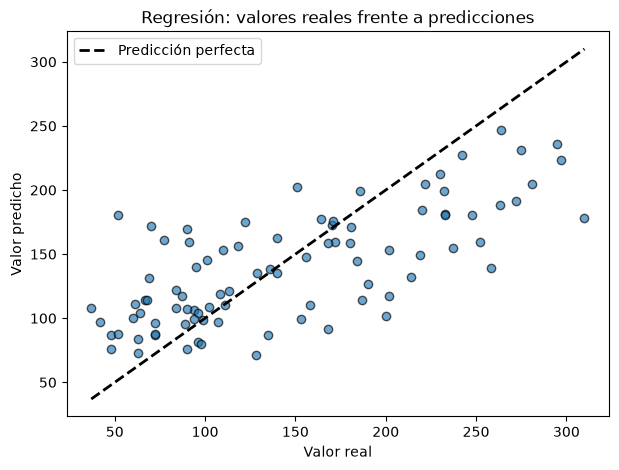

In [14]:
grafica_real_vs_pred(y_test, y_pred, metricas, model)

En el gráfico se aprecia que cada punto representa una instancia del conjunto de prueba y la línea diagonal discontinua representa la predicción perfecta, entonces cuanto más cerca esté un punto de ella, menor será el error de esa predicción, los puntos que se encuentren por encima sobreestiman y los de abajo subestiman el error.

## Conclusión

Se dividieron los datos en dos partes el 80% para entrenamiento y el 20% para prueba, mediante una validación cruzada de cinco particiones se estimó el error del modelo sin utilizar el conjunto de prueba externo reservado, luego se entrenó el modelo con los datos separados para esto y se calculó la métrica MAE sobre los datos de prueba.

Se presenta un gráfico que permite comparar los valores reales y las predicciones, en el que se puede interpretar que un error menor indica mejor precisión, pero la calidad del modelo debe interpretarse en relación con la escala de la variable objetivo.